# KAN-30 - Correlações e Diagramas de Dispersão

- **Projeto:** Spaceship Titanic - Análise Estatística
- **Responsável:** Renatta
- **Revisor:** Gustavo
- **Base analítica:** `data/processed/spaceship_titanic_clean.csv` (gerada no KAN-12)
- **Figuras exportadas em:** `report/figures/`

## Objetivo desta etapa

Medir a força e a direção da associação entre as variáveis quantitativas da base, usando os coeficientes de **Pearson** (associação linear) e de **Spearman** (associação monotônica, baseada em postos). Os resultados são apresentados em heatmaps anotados e diagramas de dispersão dos pares de maior correlação. Ao final, avaliamos a **multicolinearidade** entre as preditoras que serão usadas na regressão do KAN-31.

> Correlação mede associação, não causalidade. Um coeficiente alto indica que duas variáveis variam juntas, mas não que uma provoque a outra.

## 1. Preparação reproduzível

Usamos apenas a base de treinamento tratada no KAN-12, sem refazer a limpeza. Os caminhos são relativos à raiz do projeto, para que o notebook rode tanto da raiz quanto da pasta `notebooks/`. A semente 42 é fixada por padrão do grupo, embora as correlações em si não dependam de aleatoriedade.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

# Permite executar o notebook a partir da raiz do projeto ou da pasta notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'data').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_PATH = PROJECT_ROOT / 'data' / 'processed' / 'spaceship_titanic_clean.csv'
FIGURES_DIR = PROJECT_ROOT / 'report' / 'figures'
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

df = pd.read_csv(DATA_PATH)

print(f'Base carregada: {DATA_PATH.relative_to(PROJECT_ROOT).as_posix()}')
print(f'Dimensão: {df.shape[0]:,} passageiros x {df.shape[1]} colunas')

Base carregada: data/processed/spaceship_titanic_clean.csv
Dimensão: 8,693 passageiros x 22 colunas


## 2. Variáveis analisadas e validação dos dados

Selecionamos as variáveis **quantitativas com significado numérico**:

| Variável | Descrição |
|---|---|
| `Age` | Idade do passageiro |
| `RoomService`, `FoodCourt`, `ShoppingMall`, `Spa`, `VRDeck` | Gastos em cada serviço da nave |
| `TotalSpend` | Soma dos cinco gastos (derivada no KAN-12) |
| `GroupSize` | Número de passageiros no mesmo grupo |

Ficam de fora `Group` e `CabinNum`. Apesar de serem números, são **identificadores**: a diferença entre o grupo 10 e o grupo 20 não representa uma quantidade, então uma correlação com eles não teria interpretação.

Antes de calcular qualquer coeficiente, conferimos se as colunas existem, se não há valores ausentes ou negativos e se `TotalSpend` é de fato a soma dos componentes. Essa última verificação é importante para a análise de multicolinearidade: uma variável que é a soma exata de outras gera dependência linear perfeita.

In [2]:
SPEND_COLUMNS = ['RoomService', 'FoodCourt', 'ShoppingMall', 'Spa', 'VRDeck']
QUANT_COLUMNS = ['Age', *SPEND_COLUMNS, 'TotalSpend', 'GroupSize']

missing_columns = set(QUANT_COLUMNS) - set(df.columns)
if missing_columns:
    raise ValueError(f'Colunas obrigatórias ausentes: {sorted(missing_columns)}')

null_counts = df[QUANT_COLUMNS].isna().sum()
if (null_counts > 0).any():
    raise ValueError(f'Valores ausentes: {null_counts[null_counts > 0].to_dict()}')

negative_counts = (df[QUANT_COLUMNS] < 0).sum()
if (negative_counts > 0).any():
    raise ValueError(f'Valores negativos: {negative_counts[negative_counts > 0].to_dict()}')

total_diff = (df[SPEND_COLUMNS].sum(axis=1) - df['TotalSpend']).abs().max()
if not np.isclose(total_diff, 0):
    raise ValueError(f'TotalSpend difere da soma dos gastos (diferença máxima: {total_diff})')

quant = df[QUANT_COLUMNS]
print(f'{len(QUANT_COLUMNS)} variáveis quantitativas, {len(quant):,} observações, sem ausências nem negativos.')
print(f'TotalSpend = soma dos 5 gastos (diferença máxima: {total_diff:.1f}).')

8 variáveis quantitativas, 8,693 observações, sem ausências nem negativos.
TotalSpend = soma dos 5 gastos (diferença máxima: 0.0).


## 3. Forma das distribuições

O coeficiente de Pearson é sensível a valores extremos e mede apenas relações lineares. Por isso, antes de escolhê-lo, observamos a proporção de zeros e a assimetria (*skewness*) de cada variável.

In [3]:
shape_summary = pd.DataFrame({
    'média': quant.mean(),
    'mediana': quant.median(),
    'máximo': quant.max(),
    '% zeros': (quant == 0).mean() * 100,
    'assimetria': quant.skew(),
}).round(2)
shape_summary

,média,mediana,máximo,% zeros,assimetria
Age,28.78,27.0,79.0,2.05,0.43
RoomService,221.58,0.0,14327.0,65.24,6.38
FoodCourt,451.40,0.0,29813.0,63.83,7.17
ShoppingMall,169.95,0.0,23492.0,65.80,12.77
Spa,305.45,0.0,22408.0,62.26,7.72
VRDeck,299.09,0.0,24133.0,64.40,7.90
TotalSpend,1447.46,717.0,35987.0,41.92,4.40
GroupSize,2.04,1.0,8.0,0.00,1.89


**Interpretação.** Cada um dos cinco gastos é zero para cerca de 62% a 66% dos passageiros. Mesmo o `TotalSpend` é zero para 41,9% deles, o que inclui todos os passageiros em criossono (36,1% da base, nenhum com gasto). A assimetria dos gastos é fortemente positiva (de 4,4 a 12,8), com mediana zero e máximos acima de 14 mil. `Age` é quase simétrica (0,43), e `GroupSize` é discreta e concentrada em 1.

Nesse cenário, poucos passageiros com gastos muito altos podem dominar o coeficiente de Pearson. Por isso:

- calculamos **Pearson e Spearman lado a lado**. O Spearman usa postos e é robusto a extremos. Quando os dois coeficientes divergem muito, isso indica que a relação não é linear ou que é puxada por valores extremos;
- as correlações são calculadas nos **valores originais**, com os zeros preservados, porque zero é um valor real (o passageiro não gastou);
- a transformação `log1p` (log(1 + x), que aceita zeros) entra **apenas nos gráficos**, para tornar a nuvem de pontos legível, e sempre identificada nos eixos.

Uma ressalva: com tantos zeros, há muitos empates nos postos. O Spearman continua válido (o pandas atribui o posto médio aos empates), mas a sua interpretação passa a misturar duas coisas: "gastou ou não" e "quanto gastou".

## 4. Matrizes de correlação de Pearson e de Spearman

- **Pearson (r):** mede a intensidade da relação **linear** entre duas variáveis, usando os valores originais.
- **Spearman (ρ):** é o coeficiente de Pearson aplicado aos **postos** (ordens) dos valores. Mede relações **monotônicas** (sempre crescentes ou sempre decrescentes) e é menos afetado por valores extremos.

Os dois variam de -1 a +1. O sinal indica a direção, e o valor absoluto indica a intensidade. As duas matrizes são calculadas sobre as mesmas 8 variáveis, com os valores originais.

In [4]:
pearson = quant.corr(method='pearson')
spearman = quant.corr(method='spearman')

# Tabela de pares (cada par aparece uma única vez), ordenada por |r|.
upper = np.triu(np.ones(pearson.shape, dtype=bool), k=1)
pairs = pd.DataFrame({
    'pearson_r': pearson.where(upper).stack(),
    'spearman_rho': spearman.where(upper).stack(),
})
pairs['rho_menos_r'] = pairs['spearman_rho'] - pairs['pearson_r']
pairs = pairs.reindex(pairs['pearson_r'].abs().sort_values(ascending=False).index)
pairs.index.names = ['variável 1', 'variável 2']
pairs.round(3).head(12)

pearson_r  spearman_rho  rho_menos_r
variável 1   variável 2                                      
FoodCourt    TotalSpend      0.743         0.673       -0.070
Spa          TotalSpend      0.593         0.668        0.074
VRDeck       TotalSpend      0.588         0.639        0.051
RoomService  TotalSpend      0.234         0.535        0.300
FoodCourt    VRDeck          0.228         0.517        0.289
             Spa             0.222         0.492        0.269
ShoppingMall TotalSpend      0.222         0.511        0.289
Age          TotalSpend      0.187         0.264        0.077
             GroupSize      -0.176        -0.149        0.027
Spa          VRDeck          0.150         0.454        0.304
Age          FoodCourt       0.129         0.204        0.074
             Spa             0.123         0.193        0.070

## 5. Heatmaps anotados

Cada célula mostra o coeficiente com duas casas decimais. Exibimos apenas o triângulo inferior, porque a matriz é simétrica e a diagonal (sempre 1) não traz informação. A escala de cores é divergente e fixa entre -1 e +1: azul para correlações negativas, vermelho para positivas e cinza perto de zero. Assim, as cores dos dois heatmaps podem ser comparadas diretamente.

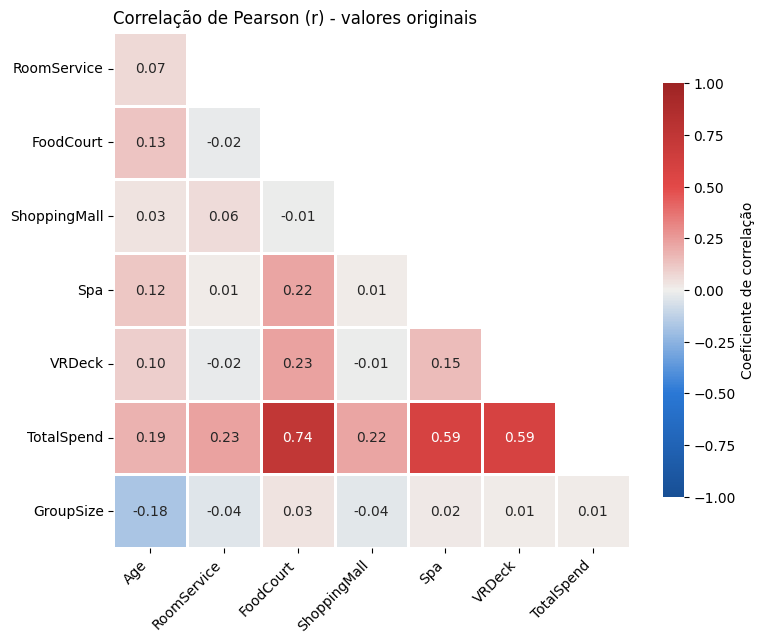

Figura exportada: report/figures/kan30_heatmap_pearson.png


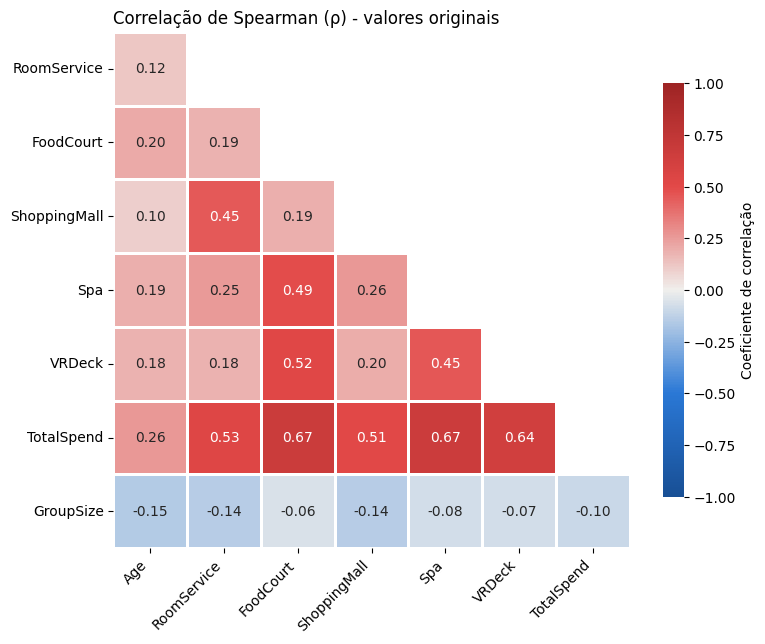

Figura exportada: report/figures/kan30_heatmap_spearman.png


In [5]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    'azul_cinza_vermelho', ['#184f95', '#2a78d6', '#f0efec', '#e34948', '#9e2424']
)


def plot_corr_heatmap(corr, title, filename):
    """Desenha o triângulo inferior da matriz, anota os coeficientes e exporta em PNG."""
    # Remove a primeira linha e a última coluna, que ficariam vazias no triângulo inferior.
    lower = corr.iloc[1:, :-1]
    mask = np.triu(np.ones(lower.shape, dtype=bool), k=1)
    fig, ax = plt.subplots(figsize=(8, 6.5))
    sns.heatmap(
        lower, mask=mask, annot=True, fmt='.2f', cmap=DIVERGING_CMAP,
        vmin=-1, vmax=1, center=0, square=True, linewidths=2, linecolor='white',
        cbar_kws={'label': 'Coeficiente de correlação', 'shrink': 0.8}, ax=ax,
    )
    ax.set_title(title, loc='left', fontsize=12)
    ax.tick_params(axis='x', rotation=45)
    plt.setp(ax.get_xticklabels(), ha='right')
    fig.tight_layout()
    output = FIGURES_DIR / filename
    fig.savefig(output, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')


plot_corr_heatmap(pearson, 'Correlação de Pearson (r) - valores originais', 'kan30_heatmap_pearson.png')
plot_corr_heatmap(spearman, 'Correlação de Spearman (ρ) - valores originais', 'kan30_heatmap_spearman.png')

## 6. Verificação exploratória: Spearman só entre quem gastou

Na tabela de pares, o Spearman fica bem acima do Pearson entre os gastos (por exemplo, `RoomService` × `ShoppingMall`: r = 0,06 e ρ = 0,45). Como 41,9% dos passageiros têm todos os gastos zerados, é possível que os zeros que aparecem **juntos** influenciem esse ρ. Como verificação exploratória, recalculamos o Spearman entre os componentes apenas para os passageiros com `TotalSpend > 0`.

A **base completa continua sendo a análise principal**. Este subconjunto só ajuda a ler as matrizes acima e não as substitui.

In [6]:
spenders = df.loc[df['TotalSpend'] > 0, SPEND_COLUMNS]
spearman_spenders = spenders.corr(method='spearman')

comparison = pd.DataFrame({
    'rho_base_completa': spearman.loc[SPEND_COLUMNS, SPEND_COLUMNS].where(upper[1:6, 1:6]).stack(),
    'rho_so_quem_gastou': spearman_spenders.where(upper[1:6, 1:6]).stack(),
})
comparison.index.names = ['variável 1', 'variável 2']
print(f'Passageiros com TotalSpend > 0: {len(spenders):,} de {len(df):,}')
comparison.round(2).sort_values('rho_so_quem_gastou')

Passageiros com TotalSpend > 0: 5,049 de 8,693


rho_base_completa  rho_so_quem_gastou
variável 1   variável 2                                         
RoomService  FoodCourt                  0.19               -0.32
             VRDeck                     0.18               -0.31
FoodCourt    ShoppingMall               0.19               -0.29
ShoppingMall VRDeck                     0.20               -0.28
RoomService  Spa                        0.25               -0.24
ShoppingMall Spa                        0.26               -0.21
Spa          VRDeck                     0.45                0.11
RoomService  ShoppingMall               0.45                0.12
FoodCourt    Spa                        0.49                0.18
             VRDeck                     0.52                0.24

### Interpretação dos resultados

**1. As correlações mais fortes são de cada gasto com `TotalSpend`.** Os maiores coeficientes da matriz são `FoodCourt` × `TotalSpend` (r = 0,74), `Spa` × `TotalSpend` (r = 0,59) e `VRDeck` × `TotalSpend` (r = 0,59). Esse resultado é esperado por construção, porque `TotalSpend` é a soma dos cinco gastos. Ele mostra quais serviços pesam mais no total, mas não é uma descoberta sobre o comportamento dos passageiros. `RoomService` e `ShoppingMall` contribuem menos (r ≈ 0,22-0,23).

**2. Entre os gastos, o Pearson é fraco.** Entre componentes diferentes, o maior r é 0,23 (`FoodCourt` × `VRDeck`), e vários pares ficam próximos de zero. Pela medida linear, gastar muito em um serviço pouco se associa a gastar muito em outro.

**3. O Spearman é bem maior, e há indícios de influência dos zeros.** Na base completa, o ρ entre os gastos chega a 0,45-0,52. Na verificação exploratória da seção 6, restrita aos 5.049 passageiros que gastaram algo, esses coeficientes ficam entre -0,32 e 0,24, e seis dos dez pares passam a ser negativos. Essa mudança é um **indício** de que a coincidência de zeros (por exemplo, passageiros em criossono não gastam em nenhum serviço) contribui para o ρ positivo da base completa. A análise não demonstra que essa seja a explicação principal, nem caracteriza perfis de consumo. Para isso seriam necessárias análises próprias.

**4. A idade e o tamanho do grupo têm associações fracas.** `Age` se correlaciona fracamente e de forma positiva com os gastos (r = 0,19 com `TotalSpend`). `Age` × `GroupSize` é a correlação negativa mais forte da base completa (r = -0,18 e ρ = -0,15). `GroupSize` praticamente não se relaciona com os gastos (|r| ≤ 0,04).

**5. Foco na magnitude.** O foco desta análise é a magnitude das associações, por isso não interpretamos p-valores.

**Implicações para as próximas etapas:**
- os diagramas de dispersão precisam preservar e deixar visíveis os zeros;
- `TotalSpend` não pode ser usado junto com os seus componentes em um mesmo modelo.

> Lembrete: todas são associações observacionais. Elas não indicam que um gasto cause o outro.

## 7. Diagramas de dispersão dos pares selecionados

### Critério de seleção

Selecionamos poucos pares, com regras definidas antes de olhar os gráficos e aplicadas às matrizes da **base completa**:

| Papel | Regra | Por que incluir |
|---|---|---|
| Relação com `TotalSpend` | maior \|r\| entre um componente e `TotalSpend` | mostra o componente que mais acompanha o total |
| Relação entre gastos | maior \|ρ\| entre dois componentes distintos | é o par em que Pearson e Spearman mais divergem, ou seja, onde os zeros podem pesar |
| Relação negativa | r mais negativo da matriz | mostra a principal associação inversa da base |

Como **verificação exploratória**, acrescentamos o par de ρ mais negativo no subconjunto `TotalSpend > 0` (seção 6), sempre identificado como tal.

### Como ler os gráficos
- O título informa a **população** de cada gráfico e o seu tamanho (n).
- Os eixos dos gastos usam `log1p(x) = log(1 + x)`. Essa transformação mantém o zero em 0 e comprime os valores altos. Ela é **só visual**: os coeficientes informados são os calculados nos valores originais.
- Os pontos com valor zero são preservados. Eles aparecem alinhados sobre os eixos, e a quantidade deles é informada no gráfico.
- `GroupSize` é discreta (1 a 8). Para os pontos não se sobreporem, aplicamos um pequeno deslocamento aleatório horizontal (*jitter*, semente 42), só no desenho, e marcamos a mediana de `Age` de cada tamanho de grupo.

In [7]:
component_pairs = pairs.loc[
    [(a, b) for a, b in pairs.index if a in SPEND_COLUMNS and b in SPEND_COLUMNS]
]
with_total = pairs.loc[[(a, b) for a, b in pairs.index if 'TotalSpend' in (a, b) and {a, b} <= set(SPEND_COLUMNS) | {'TotalSpend'}]]

selected = {
    'Relação com TotalSpend': with_total['pearson_r'].abs().idxmax(),
    'Relação entre gastos': component_pairs['spearman_rho'].abs().idxmax(),
    'Relação negativa': pairs['pearson_r'].idxmin(),
}
exploratory_pair = comparison['rho_so_quem_gastou'].idxmin()

for role, (a, b) in selected.items():
    print(f'{role:<24} {a} x {b}: r = {pairs.loc[(a, b), "pearson_r"]:.2f}, ρ = {pairs.loc[(a, b), "spearman_rho"]:.2f}')
a, b = exploratory_pair
print(f'{"Exploratório (gasto > 0)":<24} {a} x {b}: ρ = {comparison.loc[(a, b), "rho_so_quem_gastou"]:.2f}')

Relação com TotalSpend   FoodCourt x TotalSpend: r = 0.74, ρ = 0.67
Relação entre gastos     FoodCourt x VRDeck: r = 0.23, ρ = 0.52
Relação negativa         Age x GroupSize: r = -0.18, ρ = -0.15
Exploratório (gasto > 0) RoomService x FoodCourt: ρ = -0.32


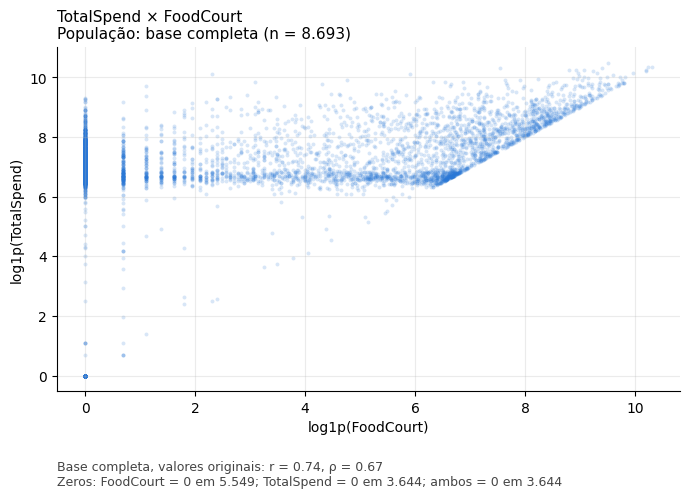

Figura exportada: report/figures/kan30_dispersao_total_TotalSpend_FoodCourt.png


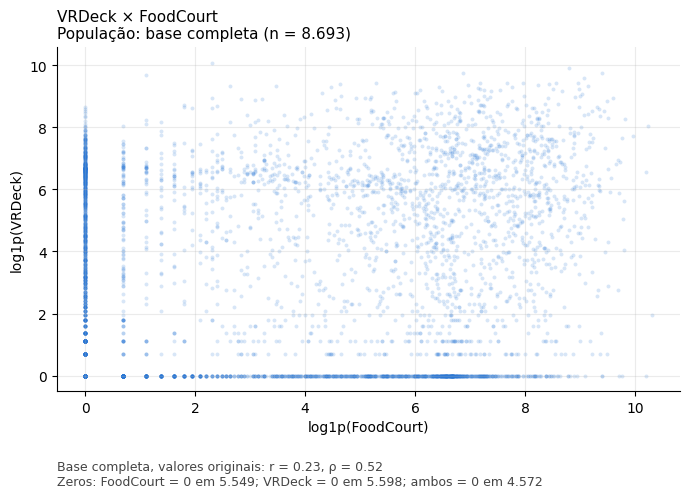

Figura exportada: report/figures/kan30_dispersao_gastos_VRDeck_FoodCourt.png


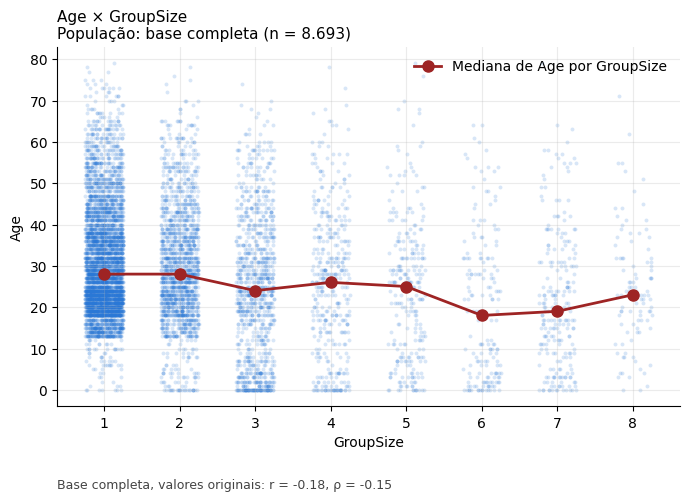

Figura exportada: report/figures/kan30_dispersao_negativa_Age_GroupSize.png


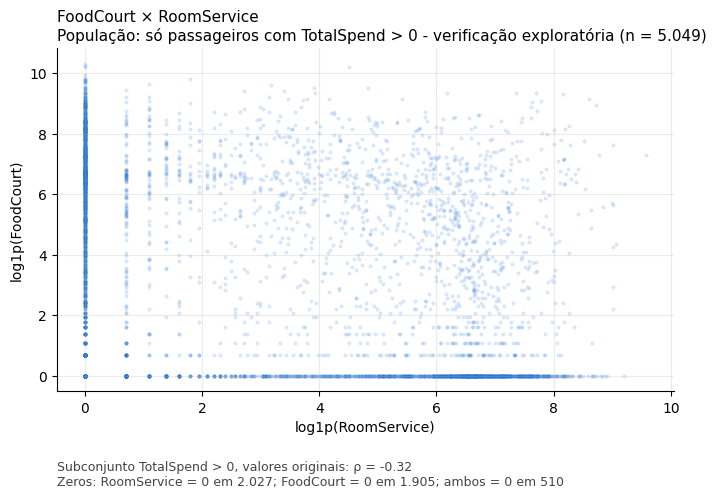

Figura exportada: report/figures/kan30_dispersao_exploratoria_FoodCourt_RoomService.png


In [8]:
POINT_COLOR = '#2a78d6'
MEDIAN_COLOR = '#9e2424'
rng = np.random.default_rng(SEED)


def fmt_int(n):
    """Inteiro com separador de milhar no padrão brasileiro (8.693)."""
    return f'{n:,}'.replace(',', '.')


def axis_values(series):
    """Gastos vão em log1p (zeros preservados em 0); demais variáveis ficam na escala original."""
    if series.name in SPEND_COLUMNS + ['TotalSpend']:
        return np.log1p(series), f'log1p({series.name})'
    return series, series.name


def plot_pair(data, x, y, population, filename, stats_text):
    """Dispersão de um par, com a população no título e os zeros contados no gráfico."""
    fig, ax = plt.subplots(figsize=(7, 5.2))
    xv, xlabel = axis_values(data[x])
    yv, ylabel = axis_values(data[y])
    if x == 'GroupSize':
        xv = xv + rng.uniform(-0.25, 0.25, size=len(xv))
    ax.scatter(xv, yv, s=8, alpha=0.18, color=POINT_COLOR, linewidths=0)

    if x == 'GroupSize':
        medians = data.groupby(x)[y].median()
        ax.plot(medians.index, medians.values, color=MEDIAN_COLOR, marker='o',
                markersize=8, linewidth=2, label=f'Mediana de {y} por {x}')
        ax.legend(loc='upper right', frameon=False)
        ax.set_xticks(medians.index)
        zero_text = ''
    else:
        x_zero, y_zero = data[x] == 0, data[y] == 0
        zero_text = (f'\nZeros: {x} = 0 em {fmt_int(x_zero.sum())}; {y} = 0 em {fmt_int(y_zero.sum())}; '
                     f'ambos = 0 em {fmt_int((x_zero & y_zero).sum())}')

    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.set_title(f'{y} × {x}\nPopulação: {population} (n = {fmt_int(len(data))})',
                 loc='left', fontsize=11)
    ax.text(0.0, -0.2, stats_text + zero_text, transform=ax.transAxes,
            fontsize=9, color='#444444', va='top')
    ax.grid(alpha=0.25)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    output = FIGURES_DIR / filename
    fig.savefig(output, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')


def coefficients_text(a, b):
    return (f'Base completa, valores originais: r = {pairs.loc[(a, b), "pearson_r"]:.2f}, '
            f'ρ = {pairs.loc[(a, b), "spearman_rho"]:.2f}')


for (a, b), slug in zip(selected.values(), ['total', 'gastos', 'negativa']):
    # A variável de menor escala ou discreta vai no eixo x.
    x, y = (b, a) if b == 'GroupSize' else (a, b)
    plot_pair(df, x, y, 'base completa', f'kan30_dispersao_{slug}_{y}_{x}.png', coefficients_text(a, b))

a, b = exploratory_pair
plot_pair(
    spenders, a, b, 'só passageiros com TotalSpend > 0 - verificação exploratória',
    f'kan30_dispersao_exploratoria_{b}_{a}.png',
    f'Subconjunto TotalSpend > 0, valores originais: ρ = {comparison.loc[(a, b), "rho_so_quem_gastou"]:.2f}',
)

### Interpretação dos diagramas

**`TotalSpend` × `FoodCourt` (base completa).** A associação é a mais forte da matriz (r = 0,74; ρ = 0,67), mas uma parte dela vem da construção da variável: como `TotalSpend` inclui `FoodCourt`, nenhum ponto fica abaixo da diagonal, onde `TotalSpend` seria menor que `FoodCourt`. Os 3.644 passageiros sem nenhum gasto aparecem no ponto (0, 0). Há também uma coluna em `FoodCourt = 0` com `TotalSpend` positivo, de quem gastou só em outros serviços. Por isso o gráfico mostra a contribuição do `FoodCourt` ao total, e não uma relação entre comportamentos independentes.

**`VRDeck` × `FoodCourt` (base completa).** Os 4.572 passageiros com os dois gastos zerados ficam concentrados na origem, e muitos outros aparecem sobre os eixos, gastando em só um dos dois serviços. Entre os pontos fora dos eixos, a nuvem é dispersa e não mostra uma tendência linear clara. O gráfico é coerente com a diferença entre r = 0,23 e ρ = 0,52: o ρ maior pode estar sendo influenciado pela quantidade de zeros que coincidem, mas o gráfico sozinho não permite atribuir a diferença a essa causa.

**`Age` × `GroupSize` (base completa).** É a correlação negativa mais forte da base, mas fraca (r = -0,18; ρ = -0,15). A mediana de idade é de 28 anos nos grupos de 1 ou 2 pessoas e de 18-19 anos nos grupos de 6 e 7, mas a tendência não é monotônica: o grupo de 8 tem mediana de 23. Os grupos maiores também mostram mais passageiros com idades muito baixas, inclusive `Age = 0`. A variação dentro de cada tamanho de grupo é grande, o que é coerente com uma correlação fraca.

**`FoodCourt` × `RoomService` (só `TotalSpend > 0`, exploratório).** Neste subconjunto o ρ é negativo (-0,32), e o gráfico mostra muitos passageiros que gastam em um dos dois serviços e não no outro, sobre os eixos. Esse padrão serve apenas para entender por que o coeficiente muda em relação à base completa. Ele não caracteriza perfis de consumo e não substitui a análise principal.

**Sobre a escala.** Todos os eixos de gasto usam `log1p` apenas para a visualização. Os coeficientes citados são os calculados nos valores originais, e os zeros foram mantidos em todos os gráficos.

### 7.1 Pairplot compacto

O pairplot reúne, em uma única figura, as dispersões de todos os pares de um pequeno conjunto de variáveis, com a distribuição de cada uma na diagonal. Ele complementa os gráficos dedicados acima, sem substituí-los.

- **Variáveis:** `Age`, `FoodCourt`, `VRDeck` e `TotalSpend`, que já foram analisadas nas seções anteriores e compõem os pares selecionados de relação com `TotalSpend` e de relação entre gastos. `GroupSize` fica de fora porque é discreta (1 a 8) e já aparece no gráfico dedicado com *jitter*.
- **População:** base completa (n = 8.693).
- **Eixos:** os gastos aparecem em `log1p` (só para a visualização, com os zeros preservados em 0), e `Age` fica na escala original. A transformação está indicada no nome de cada eixo.
- O pairplot mostra só o triângulo inferior, porque o superior repetiria os mesmos pares espelhados.

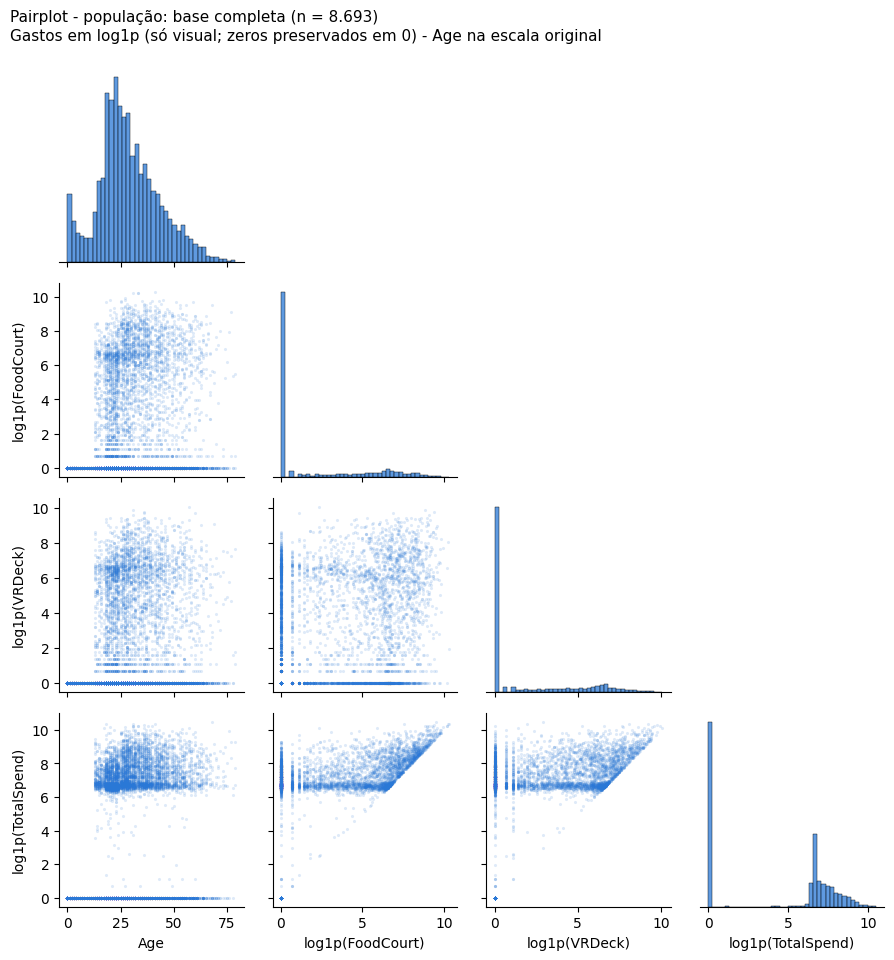

Figura exportada: report/figures/kan30_pairplot.png


In [9]:
PAIRPLOT_COLUMNS = ['Age', 'FoodCourt', 'VRDeck', 'TotalSpend']

pair_data = pd.DataFrame()
for column in PAIRPLOT_COLUMNS:
    values, label = axis_values(df[column])
    pair_data[label] = values

# PairGrid permite escalas verticais independentes nos histogramas da diagonal.
grid = sns.PairGrid(pair_data, corner=True, diag_sharey=False, height=2.3)
grid.map_diag(sns.histplot, color=POINT_COLOR, bins=40)
grid.map_lower(sns.scatterplot, s=5, alpha=0.15, color=POINT_COLOR, linewidth=0)
grid.figure.suptitle(
    f'Pairplot - população: base completa (n = {fmt_int(len(df))})\n'
    'Gastos em log1p (só visual; zeros preservados em 0) - Age na escala original',
    x=0.02, y=1.04, ha='left', fontsize=11,
)
output = FIGURES_DIR / 'kan30_pairplot.png'
grid.figure.savefig(output, dpi=150, bbox_inches='tight')
plt.show()
print(f'Figura exportada: {output.relative_to(PROJECT_ROOT).as_posix()}')

**Interpretação.** O pairplot reproduz, em conjunto, os padrões já descritos nos gráficos dedicados:
- **Diagonal:** a barra em 0 domina os histogramas de `FoodCourt` e `VRDeck` e responde por 41,9% do `TotalSpend`, o que confirma a massa de zeros que motivou o uso do Spearman e do `log1p`. A distribuição de `Age` tem um pico em 0 e se concentra entre 18 e 40 anos.
- **`Age` × gastos:** nenhum dos 806 passageiros com menos de 13 anos tem gasto registrado, todos aparecem na linha do zero. Acima dessa idade, a nuvem é dispersa, o que é coerente com a correlação fraca entre `Age` e `TotalSpend` (r = 0,19).
- **Gastos × `TotalSpend`:** a borda diagonal aparece de novo, por construção, já que o total inclui cada componente.
- **`FoodCourt` × `VRDeck`:** a nuvem dispersa e os pontos sobre os eixos são os mesmos do gráfico dedicado.

Os coeficientes de referência continuam sendo os das matrizes da seção 4, calculados nos valores originais. O `log1p` é apenas visual.

## 8. Multicolinearidade entre as preditoras do KAN-31

A **multicolinearidade** acontece quando uma preditora pode ser bem explicada pelas outras. Ela não enviesa as previsões de uma regressão linear, mas aumenta a variância dos coeficientes estimados, o que pode torná-los instáveis e difíceis de interpretar individualmente.

O **VIF** (*Variance Inflation Factor*) de uma coluna *j* é calculado regredindo essa coluna sobre todas as outras colunas da matriz de desenho, com intercepto, e aplicando:

$$\mathrm{VIF}_j = \frac{1}{1 - R^2_j}$$

Um VIF igual a 1 indica que a coluna não tem relação linear com as demais. Um VIF de 5 indica que a variância do coeficiente está 5 vezes maior do que seria sem essa sobreposição.

**Escopo desta seção:**
- as preditoras são as previstas no KAN-31: `Age`, `HomePlanet`, `CabinDeck`, `VIP` e `GroupSize`;
- `TotalSpend` é a variável resposta e **não** entra no cálculo, porque o VIF olha apenas para as preditoras;
- nenhuma regressão de `TotalSpend` é ajustada aqui;
- nenhuma variável é excluída automaticamente por ultrapassar um limite de VIF. Os resultados servem de subsídio para as decisões do KAN-31.

### 8.1 Codificação das variáveis categóricas

As variáveis categóricas entram como variáveis indicadoras (*dummies*), com uma **categoria de referência** omitida para evitar a dependência linear perfeita com o intercepto:

| Variável | Referência | Por quê |
|---|---|---|
| `HomePlanet` | `Earth` | categoria mais frequente |
| `CabinDeck` | `F` | categoria mais frequente |
| `VIP` | `False` | ausência da característica |

O intercepto entra na matriz de desenho porque o modelo do KAN-31 terá intercepto, e sem ele os R² auxiliares ficariam incorretos. O intercepto **não recebe VIF** e não é interpretado como preditora.

In [10]:
PREDICTORS = ['Age', 'HomePlanet', 'CabinDeck', 'VIP', 'GroupSize']
REFERENCE = {'HomePlanet': 'Earth', 'CabinDeck': 'F', 'VIP': False}

X_parts = [df[['Age', 'GroupSize']].astype(float)]
term_columns = {'Age': ['Age'], 'GroupSize': ['GroupSize']}
for var, ref in REFERENCE.items():
    levels = [lvl for lvl in sorted(df[var].unique(), key=str) if lvl != ref]
    dummies = pd.DataFrame({f'{var}_{lvl}': (df[var] == lvl).astype(float) for lvl in levels})
    X_parts.append(dummies)
    term_columns[var] = list(dummies.columns)

assert set(term_columns) == set(PREDICTORS), 'Todas as preditoras previstas devem estar codificadas.'

X = pd.concat(X_parts, axis=1)
X.insert(0, 'const', 1.0)

rank = np.linalg.matrix_rank(X.values)
print(f'Matriz de desenho: {X.shape[0]:,} linhas x {X.shape[1]} colunas (incluindo o intercepto); posto = {rank}')
if rank < X.shape[1]:
    raise ValueError('A matriz de desenho tem dependência linear perfeita; revise a codificação.')
print('Colunas:', ', '.join(X.columns))

Matriz de desenho: 8,693 linhas x 13 colunas (incluindo o intercepto); posto = 13
Colunas: const, Age, GroupSize, HomePlanet_Europa, HomePlanet_Mars, CabinDeck_A, CabinDeck_B, CabinDeck_C, CabinDeck_D, CabinDeck_E, CabinDeck_G, CabinDeck_T, VIP_True


### 8.2 VIF por coluna e GVIF por variável

As duas medidas olham para objetos diferentes:

- **VIF por coluna.** É calculado para cada coluna da matriz de desenho, exceto o intercepto, pela fórmula da seção 8. No caso de uma categórica, cada *dummy* recebe o seu próprio VIF, e esse valor **depende da categoria de referência**: trocar a referência muda as colunas e, com elas, os VIFs.
- **GVIF por variável.** O VIF generalizado (Fox e Monette, 1992) trata o conjunto de colunas de uma variável como um bloco único e **não depende da categoria de referência**:

$$\mathrm{GVIF} = \frac{\det(R_{11})\,\det(R_{22})}{\det(R)}$$

Nessa fórmula, *R* é a matriz de correlação de todas as colunas exceto o intercepto, *R₁₁* é o bloco das colunas da variável e *R₂₂* é o bloco das demais colunas.

**Ajuste pelo número de colunas.** O GVIF de uma variável com *df* colunas não é comparável diretamente ao de uma variável com uma única coluna. Por isso usamos dois ajustes:

$$\mathrm{GVIF}_{\text{ajustado}} = \mathrm{GVIF}^{1/(2\,df)} \qquad\qquad \left(\mathrm{GVIF}^{1/(2\,df)}\right)^2 = \mathrm{GVIF}^{1/df}$$

- O primeiro, GVIF^(1/(2·df)), está na escala do **erro-padrão**, ou seja, da raiz do VIF. É ele que permite comparar variáveis com números diferentes de colunas.
- O segundo, GVIF^(1/df), está na escala de um VIF comum. Na tabela abaixo aparece como **"equivalente a VIF"**.

Para uma variável de uma só coluna (*df* = 1), GVIF = VIF e GVIF^(1/df) = VIF.

In [11]:
def vif_by_column(design):
    """VIF de cada coluna (exceto o intercepto), via regressão auxiliar com intercepto."""
    values = design.values
    result = {}
    for j, col in enumerate(design.columns):
        if col == 'const':
            continue
        y_j = values[:, j]
        others = np.delete(values, j, axis=1)
        beta, *_ = np.linalg.lstsq(others, y_j, rcond=None)
        resid = y_j - others @ beta
        r2 = 1 - resid @ resid / ((y_j - y_j.mean()) @ (y_j - y_j.mean()))
        result[col] = 1 / (1 - r2)
    return pd.Series(result, name='VIF')


vif_columns = vif_by_column(X)
column_table = pd.DataFrame({
    'VIF': vif_columns,
    'n na categoria': X.drop(columns='const').sum().where(lambda s: s.index.str.contains('_')).astype('Int64'),
})
column_table.round(2)

,VIF,n na categoria
Age,1.13,<NA>
GroupSize,1.09,<NA>
HomePlanet_Europa,7.99,2174
HomePlanet_Mars,1.62,1804
CabinDeck_A,2.21,262
CabinDeck_B,4.44,817
CabinDeck_C,4.24,761
CabinDeck_D,1.55,507
CabinDeck_E,1.26,885
CabinDeck_G,1.70,2588


In [12]:
R = X.drop(columns='const').corr().values
cols = list(X.drop(columns='const').columns)
det_R = np.linalg.det(R)

gvif_rows = []
for var, var_cols in term_columns.items():
    idx = [cols.index(c) for c in var_cols]
    rest = [i for i in range(len(cols)) if i not in idx]
    gvif = np.linalg.det(R[np.ix_(idx, idx)]) * np.linalg.det(R[np.ix_(rest, rest)]) / det_R
    gvif_rows.append({
        'variável': var,
        'df': len(var_cols),
        'GVIF': gvif,
        'GVIF^(1/(2df))': gvif ** (1 / (2 * len(var_cols))),
        'equivalente a VIF': gvif ** (1 / len(var_cols)),
    })

gvif_table = pd.DataFrame(gvif_rows).set_index('variável').sort_values('equivalente a VIF', ascending=False)
gvif_table.round(2)

,df,GVIF,GVIF^(1/(2df)),equivalente a VIF
variável,,,,
HomePlanet,2,10.34,1.79,3.22
CabinDeck,7,10.70,1.18,1.40
Age,1,1.13,1.06,1.13
GroupSize,1,1.09,1.04,1.09
VIP,1,1.05,1.02,1.05


### 8.3 De onde vem a sobreposição

Para entender os valores acima, cruzamos as duas variáveis categóricas. A tabela descreve as preditoras e não é uma nova análise de associação.

In [13]:
pd.crosstab(df['CabinDeck'], df['HomePlanet'], margins=True, margins_name='Total')

HomePlanet,Earth,Europa,Mars,Total
CabinDeck,,,,
A,0,262,0,262
B,0,817,0,817
C,0,761,0,761
D,1,195,311,507
E,407,134,344,885
F,1719,0,1149,2868
G,2588,0,0,2588
T,0,5,0,5
Total,4715,2174,1804,8693


### Interpretação

**`Age`, `GroupSize` e `VIP`: pouca evidência de multicolinearidade.** Os VIFs ficam entre 1,05 e 1,13. A parte de cada uma dessas variáveis explicada linearmente pelas demais preditoras é pequena (R² auxiliar entre 0,05 e 0,12).

**`HomePlanet` e `CabinDeck`: sobreposição moderada entre si.**
- GVIF: 10,34 para `HomePlanet` (*df* = 2) e 10,70 para `CabinDeck` (*df* = 7).
- Ajustados pelo número de colunas, GVIF^(1/(2·df)) dá 1,79 e 1,18, respectivamente. Na escala de um VIF comum (GVIF^(1/df)), isso equivale a 3,22 e 1,40.
- Entre as colunas, o maior VIF é o de `HomePlanet_Europa` (7,99), seguido de `CabinDeck_B` (4,44) e `CabinDeck_C` (4,24). Esses valores dependem das referências escolhidas (`Earth` e `F`).

A tabela cruzada mostra a origem da sobreposição: os decks A, B, C e T só têm passageiros de Europa, e o deck G só tem passageiros de Earth. Parte da informação de uma variável, portanto, já está na outra. Na regressão do KAN-31, isso pode tornar **difícil interpretar separadamente** os coeficientes de `HomePlanet` e de `CabinDeck`. O impacto concreto só poderá ser avaliado quando o modelo for ajustado.

**Nenhuma variável foi excluída.** Os limites usuais (VIF de 5 ou de 10) são convenções, e não regras estatísticas. A decisão fica para o KAN-31, que pode, por exemplo, manter as duas variáveis e interpretá-las em conjunto, usar só uma delas ou agrupar decks. Cada opção muda a pergunta que o modelo responde.

**Limitações:**
- O VIF de cada *dummy* depende da categoria de referência. O GVIF da variável inteira não depende dela.
- `CabinDeck_T` tem só 5 passageiros. O VIF baixo (1,02) não indica um coeficiente confiável: com tão poucas observações, a estimativa tende a ser imprecisa por escassez de dados, e não por colinearidade.
- O VIF mede apenas dependência **linear** entre as preditoras. Ele não diz nada sobre a relação delas com `TotalSpend`, nem considera interações que o KAN-31 venha a incluir.
- O cálculo usa a base completa (n = 8.693), com a codificação descrita acima. Mudanças nas preditoras ou na codificação exigem recalcular.

## 9. Síntese

**Correlações (base completa, valores originais).**
- As correlações mais fortes são de cada gasto com `TotalSpend`. A maior é a de `FoodCourt` (r = 0,74; ρ = 0,67), em parte por construção, já que `TotalSpend` é a soma dos gastos.
- Entre os componentes do gasto, o Pearson é fraco (no máximo r = 0,23).
- O Spearman entre os componentes é maior (até ρ = 0,52). Na verificação exploratória restrita a `TotalSpend > 0`, esses coeficientes ficam entre -0,32 e 0,24, o que é um indício de que os zeros coincidentes influenciam o ρ da base completa. A análise não demonstra a explicação.
- A relação negativa mais forte é `Age` × `GroupSize` (r = -0,18), que é fraca.

**Dispersões.** Foram produzidos quatro gráficos, selecionados por critério explícito. Três são da base completa (relação com `TotalSpend`, relação entre gastos e relação negativa) e um é exploratório, do subconjunto `TotalSpend > 0`. Um pairplot compacto (`Age`, `FoodCourt`, `VRDeck` e `TotalSpend`, base completa) reúne esses pares em uma única figura. Todos os gráficos usam `log1p` só na visualização dos gastos e mantêm os zeros.

**Multicolinearidade das preditoras do KAN-31.**
- `Age`, `GroupSize` e `VIP` mostram pouca evidência de multicolinearidade.
- `HomePlanet` e `CabinDeck` se sobrepõem, porque vários decks pertencem a um único planeta. Isso pode dificultar a interpretação separada dos seus coeficientes no KAN-31.
- Nenhuma variável foi excluída.

**Pontos de atenção para o KAN-31:**
- não usar `TotalSpend` junto com os seus componentes em um mesmo modelo;
- decidir como tratar a sobreposição entre `HomePlanet` e `CabinDeck`;
- levar em conta que o deck T tem só 5 passageiros.

**Limitações gerais.** Todas as associações são observacionais e não indicam causalidade. A interpretação prioriza a magnitude dos coeficientes. O `log1p` é apenas visual. O subconjunto `TotalSpend > 0` é exploratório e não substitui a análise principal.

In [14]:
exported = sorted(p.name for p in FIGURES_DIR.glob('kan30_*.png'))
print(f'{len(exported)} figuras do KAN-30 em {FIGURES_DIR.relative_to(PROJECT_ROOT).as_posix()}/:')
for name in exported:
    print(f'  - {name}')

7 figuras do KAN-30 em report/figures/:
  - kan30_dispersao_exploratoria_FoodCourt_RoomService.png
  - kan30_dispersao_gastos_VRDeck_FoodCourt.png
  - kan30_dispersao_negativa_Age_GroupSize.png
  - kan30_dispersao_total_TotalSpend_FoodCourt.png
  - kan30_heatmap_pearson.png
  - kan30_heatmap_spearman.png
  - kan30_pairplot.png
